# Good Seed · Verificación automática de edad en cajas

**Pregunta de negocio:** ¿puede un modelo de visión artificial ayudar a una cadena de supermercados a no vender alcohol a menores de edad, a partir de la foto que toman las cámaras de las cajas?

**Respuesta corta:** sí, como apoyo para decidir a quién pedir identificación, no como sustituto de la identificación. El modelo final (ResNet50 con ajuste fino) estima la edad con un **error absoluto medio de 6.30 años**, por debajo de la meta de 8, pero sobreestima la edad de los adolescentes en 6.7 años en promedio. Con cualquier umbral de 18 a 30 años, más del 1% de los menores sería clasificado como adulto.

| Sección | Contenido |
|---|---|
| 1 | Problema de negocio |
| 2 | Datos |
| 3 | Análisis exploratorio |
| 4 | Metodología |
| 5 | Comparación de modelos |
| 6 | Error por grupo de edad |
| 7 | Política de umbral |
| 8 | Lógica de negocio |
| 9 | Conclusiones |
| 10 | Salvedades |
| 11 | Fuentes |

*Todos los números de este notebook se leen de `resultados/metricas.json`, generado por `src/evaluacion.py`. Ninguna celda vuelve a entrenar modelos: el entrenamiento se ejecutó con `script/entrenar.py`.*

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

RANDOM_STATE = 12345

RAIZ = Path.cwd()
while not (RAIZ / 'resultados' / 'metricas.json').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
FIGURAS = RAIZ / 'figures'
metricas = json.loads((RAIZ / 'resultados' / 'metricas.json').read_text(encoding='utf-8'))


def figura(nombre):
    display(Image(filename=str(FIGURAS / nombre), width=950))

## 1. Problema de negocio

Good Seed es una cadena de supermercados que vende alcohol y debe impedir su venta a menores de 18 años. Sus cajas cuentan con cámaras que se activan en cada compra de alcohol. La cadena quiere saber si un modelo puede **estimar la edad de la persona a partir de esa foto** y usar la estimación para reforzar el cumplimiento de la ley.

El problema es una **regresión**: el modelo predice un número continuo, la edad en años. La métrica principal es el **MAE** (*Mean Absolute Error*, error absoluto medio): el promedio, en años, de la diferencia absoluta entre la edad real y la estimada. La meta es un MAE ≤ 8 en el conjunto de prueba.

Para el negocio, el MAE global no basta. Lo que importa es el error alrededor de los 18 años y en qué dirección se equivoca el modelo: sobreestimar la edad de un menor implica riesgo legal; subestimar la de un adulto implica pedirle identificación sin necesidad.

## 2. Datos

- **Conjunto:** APPA-REAL (ChaLearn Looking at People): 7,591 fotografías de rostros con la **edad real** de cada persona (`labels.csv`: `file_name`, `real_age`; carpeta `final_files/`).
- **Cita:** Agustsson, E., Timofte, R., Escalera, S., Baró, X., Guyon, I. y Rothe, R. (2017). *Apparent and real age estimation in still images with deep residual regressors on APPA-REAL database*. IEEE International Conference on Automatic Face & Gesture Recognition (FG 2017).
- **Privacidad:** las fotografías son de personas reales y tienen licencia de uso para investigación. Ninguna se publica en este repositorio, ni en las figuras ni en las salidas de los notebooks.

## 3. Análisis exploratorio

El análisis exploratorio completo, con la verificación de integridad y las características de las imágenes, está en `notebooks/referencia_tripleten.ipynb`. Aquí se resumen los hallazgos que condicionan el modelo.

In [2]:
labels = pd.read_csv(RAIZ / 'data' / 'labels.csv')
rangos = [0, 12, 17, 24, 34, 49, 64, np.inf]
nombres = ['0-12', '13-17', '18-24', '25-34', '35-49', '50-64', '65+']
labels['grupo'] = pd.cut(labels['real_age'], bins=rangos, labels=nombres, include_lowest=True)

resumen = labels['grupo'].value_counts().sort_index().to_frame('fotos')
resumen['porcentaje'] = (resumen['fotos'] / len(labels) * 100).round(1)

corte = int(len(labels) * 0.25)
diferencia_orden = labels['real_age'].iloc[:corte].mean() - labels['real_age'].iloc[corte:].mean()

display(labels['real_age'].describe().round(1).to_frame('edad real'))
display(resumen)
print(f'Diferencia de edad media entre el primer 25% del archivo y el resto: {diferencia_orden:+.1f} años')

,edad real
count,7591.0
mean,31.2
std,17.1
min,1.0
25%,20.0
50%,29.0
75%,41.0
max,100.0


,fotos,porcentaje
grupo,,
0-12,815,10.7
13-17,688,9.1
18-24,1297,17.1
25-34,2071,27.3
35-49,1584,20.9
50-64,789,10.4
65+,347,4.6


Diferencia de edad media entre el primer 25% del archivo y el resto: -2.1 años


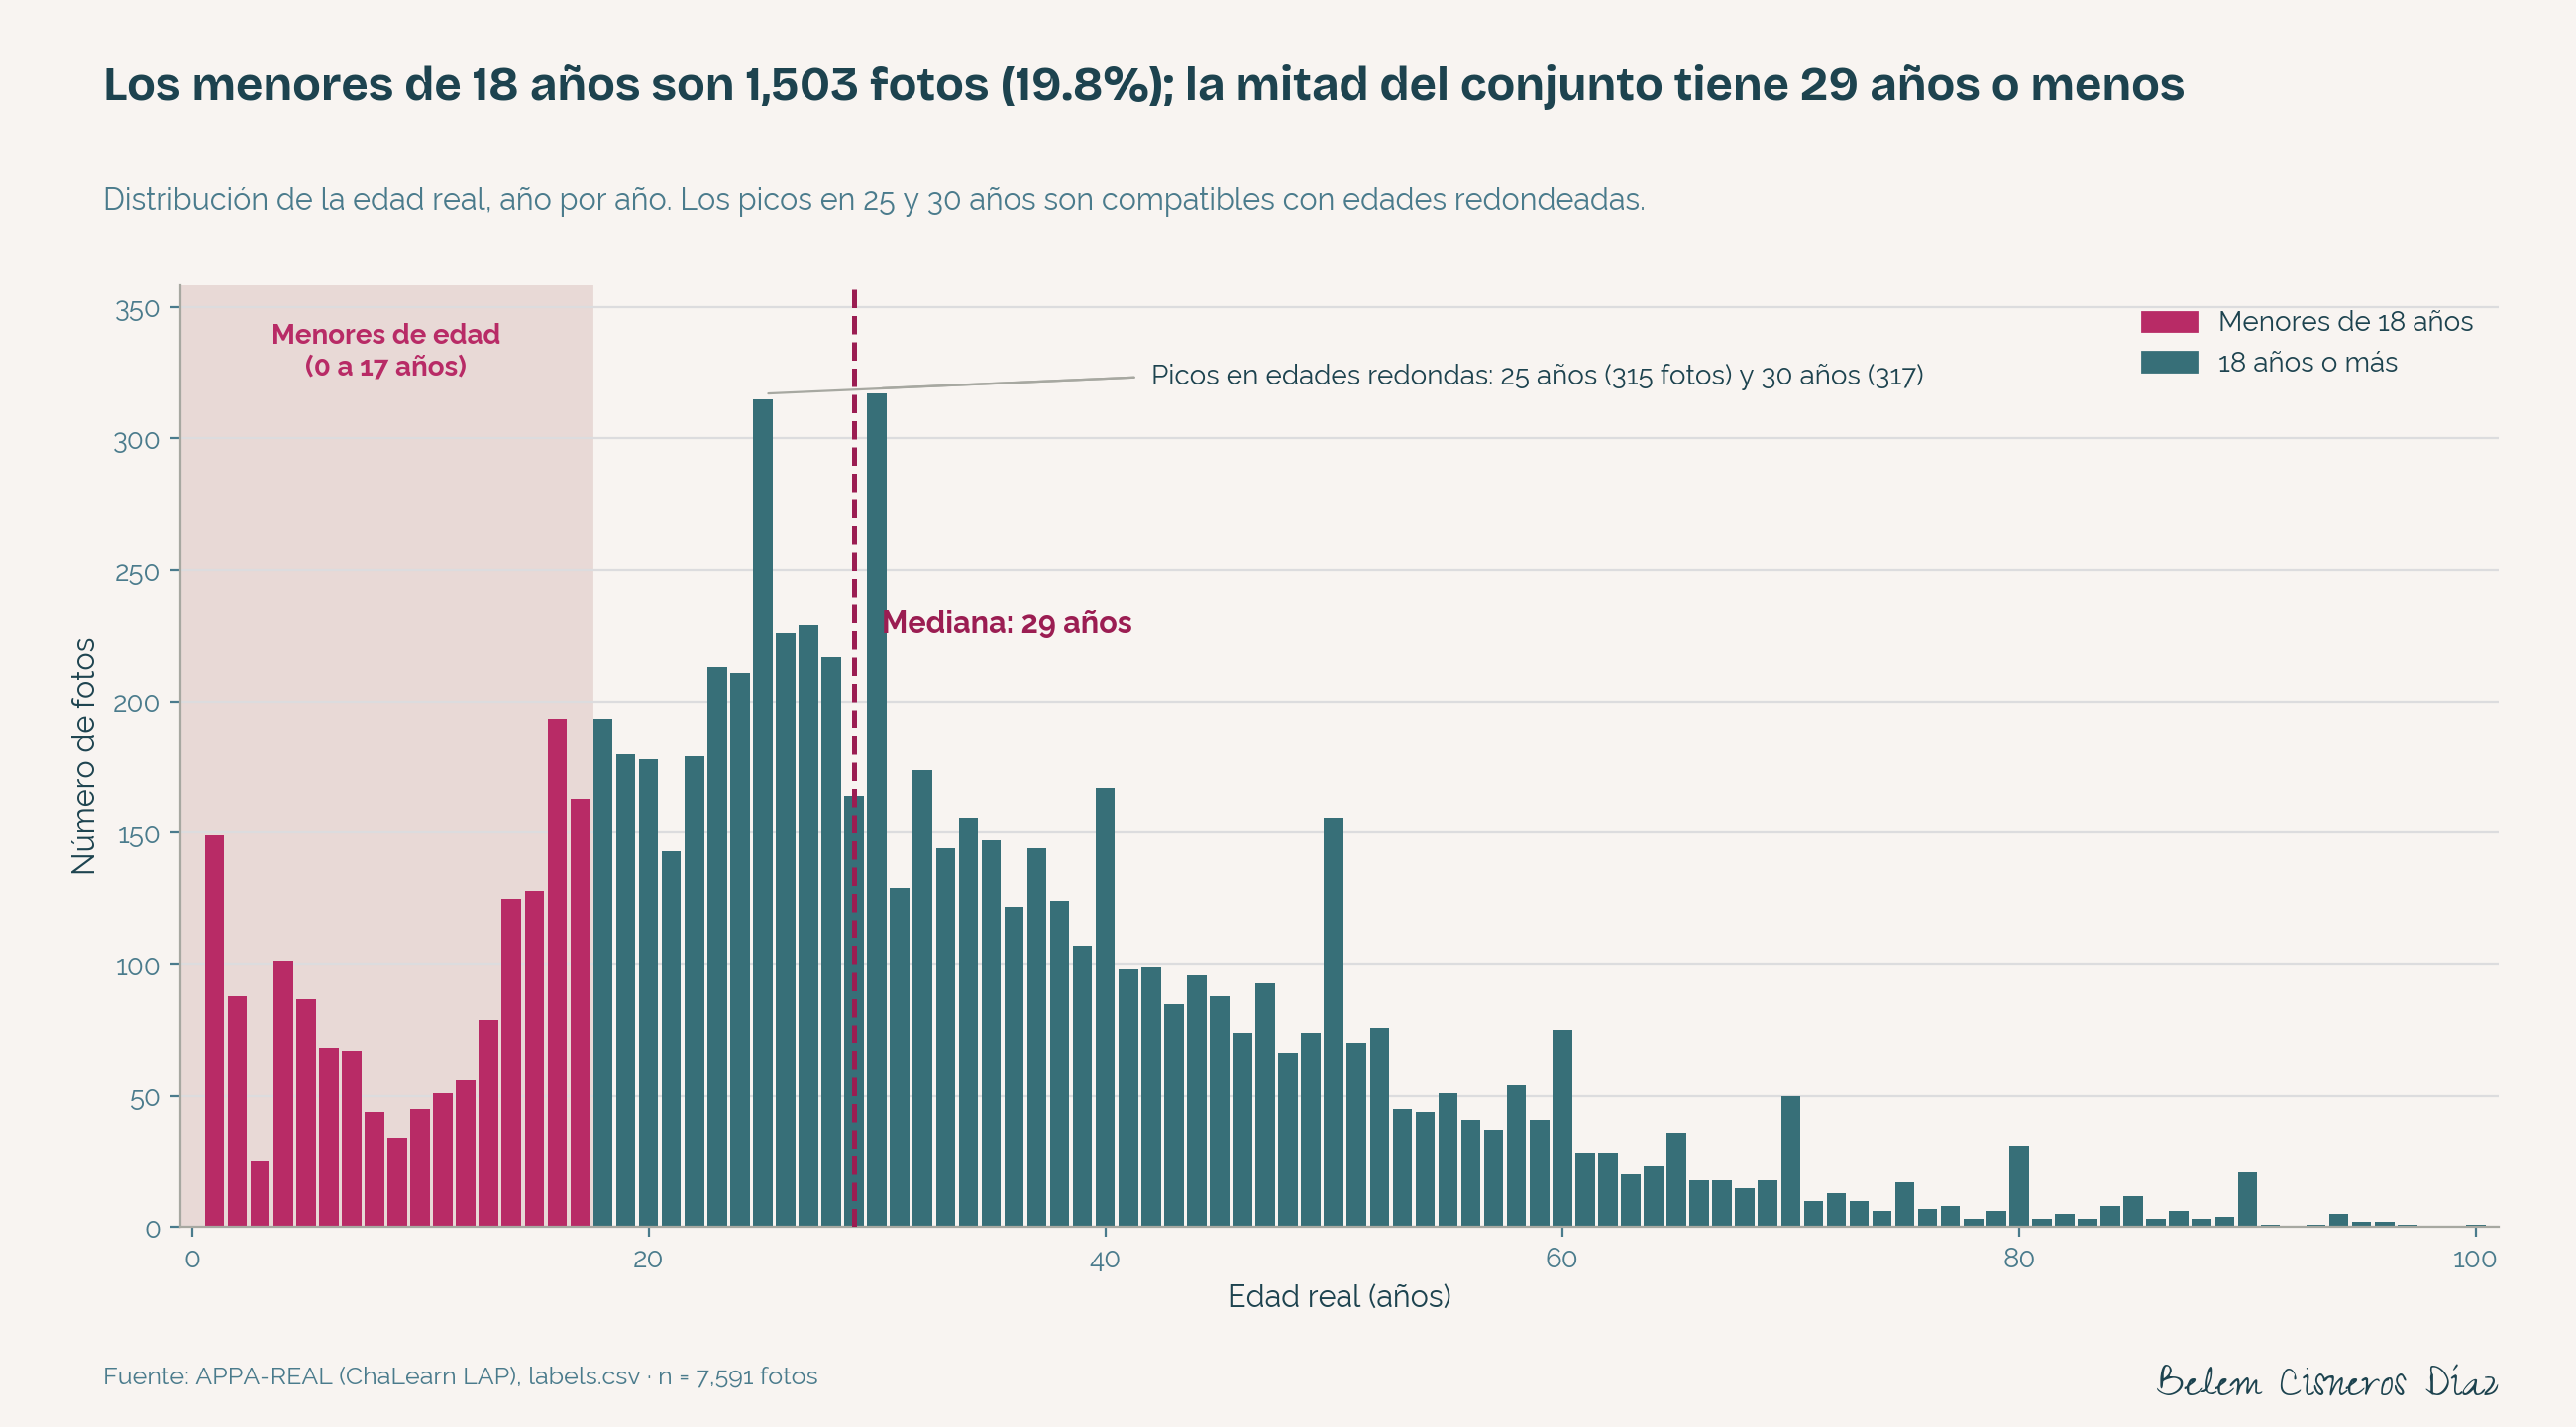

In [3]:
figura('01_distribucion_edades.png')

**Hallazgos que condicionan el modelo**

1. **Representación desigual.** El grupo 25-34 concentra el 27.3% de las fotos y el 65+ apenas el 4.6%. Los menores de 18 años son el 19.8%. El modelo aprenderá mejor las edades más frecuentes, por lo que se evalúa el error por grupo y no solo el global.
2. **Edades redondas.** Las edades más frecuentes son 30 y 25 años, muy por encima de sus vecinas, un patrón compatible con edades declaradas y redondeadas.
3. **El archivo no está en orden aleatorio.** El primer 25% de las filas es, en promedio, 2.1 años más joven que el resto. Como `flow_from_dataframe` asigna a validación el primer 25% de las filas, las filas se mezclan antes de dividir.
4. **Imágenes heterogéneas.** Hay 2,293 tamaños distintos, de 47 a 4,466 píxeles por lado, todos recortes casi cuadrados del rostro en RGB. Se redimensionan a 224 × 224, el tamaño de entrada de ResNet50.

## 4. Metodología

1. **Mezcla y división.** Las filas de `labels.csv` se mezclan con `RANDOM_STATE = 12345`. Se reserva el 25% para validación (1,897 fotos, de las cuales 366 son de menores) y el 75% para entrenamiento (5,694). La validación funciona como conjunto de prueba.
2. **Preprocesamiento.** Redimensionamiento a 224 × 224 y normalización de píxeles al rango de 0 a 1 (`rescale=1/255`). Solo se aplica reflejo horizontal como aumento de datos en entrenamiento, porque un rostro reflejado sigue siendo plausible frente a una cámara de caja.
3. **Tres modelos.**
   - **Modelo 0 · Constante.** Predice siempre la mediana de edad del entrenamiento. Es la línea base: la mediana es el valor constante que minimiza el MAE.
   - **Modelo 1 · ResNet50 congelada.** Red preentrenada en ImageNet sin modificar, con una cabeza entrenable (`GlobalAveragePooling2D` + `Dense(1, relu)`). Se entrenan solo los 2,049 parámetros de la cabeza, con Adam y tasa de aprendizaje de 0.001, durante hasta 5 épocas.
   - **Modelo 2 · ResNet50 con ajuste fino.** La misma arquitectura con sus 23.6 millones de parámetros entrenables, Adam con tasa de 0.0001 y hasta 20 épocas.
4. **Entrenamiento.** Pérdida MSE (error cuadrático medio) y métrica MAE. Parada temprana si el MAE de validación no mejora en 3 épocas, con restauración de los mejores pesos. Se entrenó localmente con CPU (Apple M5, 16 GB de RAM). Las reglas de contingencia previstas (bajar a 160 × 160 si una época tardaba más de 15 minutos, o a lotes de 16 si la memoria se saturaba) no se activaron: la primera época tardó 454 segundos.
5. **Evaluación.** MAE global y por grupo de edad, **sesgo** (promedio de edad estimada menos edad real), política de umbral e intervalos de confianza del 95% por *bootstrap* (1,000 remuestreos con reemplazo de las predicciones de validación).

## 5. Comparación de modelos

In [4]:
registros = {numero: pd.read_csv(RAIZ / 'resultados' / f'registro_modelo_{numero}.csv') for numero in [1, 2]}
comparacion = pd.DataFrame({
    'modelo': ['0 · Constante (mediana)', '1 · ResNet50 congelada', '2 · ResNet50 con ajuste fino'],
    'MAE de validación': [metricas['mae'][f'modelo_{k}'] for k in [0, 1, 2]],
    'desviación estándar de las estimaciones': [metricas['desviacion_estandar_estimaciones'][f'modelo_{k}'] for k in [0, 1, 2]],
    'épocas ejecutadas': ['—', len(registros[1]), len(registros[2])],
    'mejor época': ['—', int(registros[1]['val_mae'].idxmin()) + 1, int(registros[2]['val_mae'].idxmin()) + 1],
}).set_index('modelo')
display(comparacion.round(2))
intervalo = metricas['intervalos_95_bootstrap']['mae_global']
print(f'Modelo 2: MAE {metricas["mae"]["modelo_2"]:.2f} años (IC 95%: {intervalo[0]:.2f} a {intervalo[1]:.2f})')

,MAE de validación,desviación estándar de las estimaciones,épocas ejecutadas,mejor época
modelo,,,,
0 · Constante (mediana),13.05,0.00,—,—
1 · ResNet50 congelada,13.08,1.06,4,1
2 · ResNet50 con ajuste fino,6.30,14.45,17,14


Modelo 2: MAE 6.30 años (IC 95%: 6.05 a 6.55)


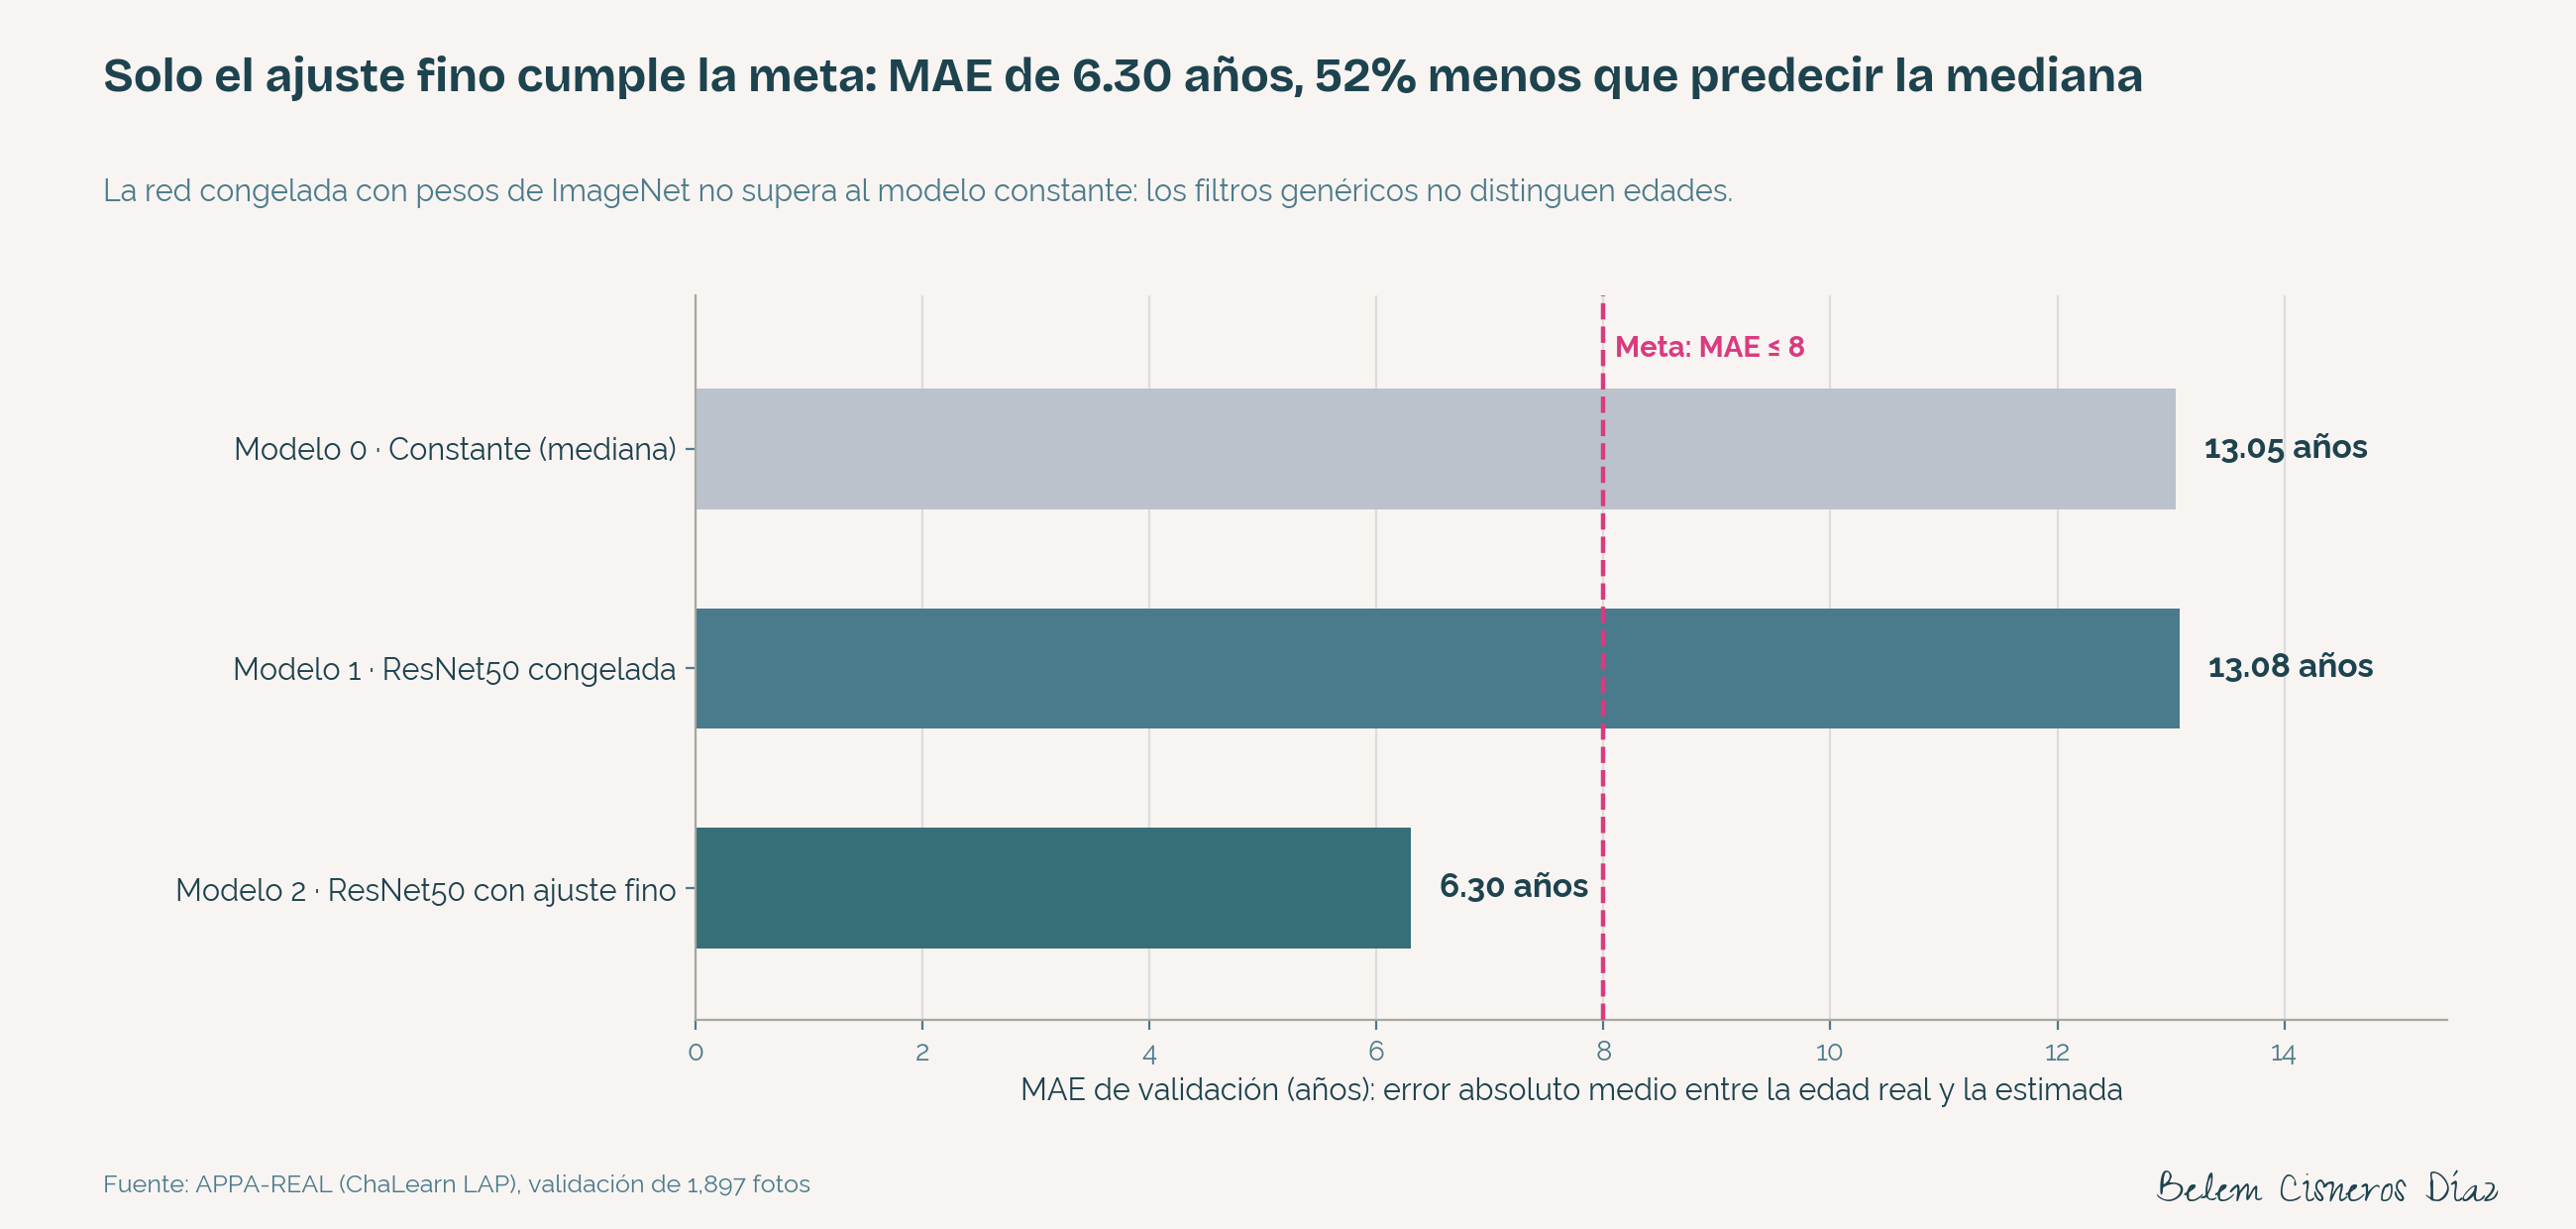

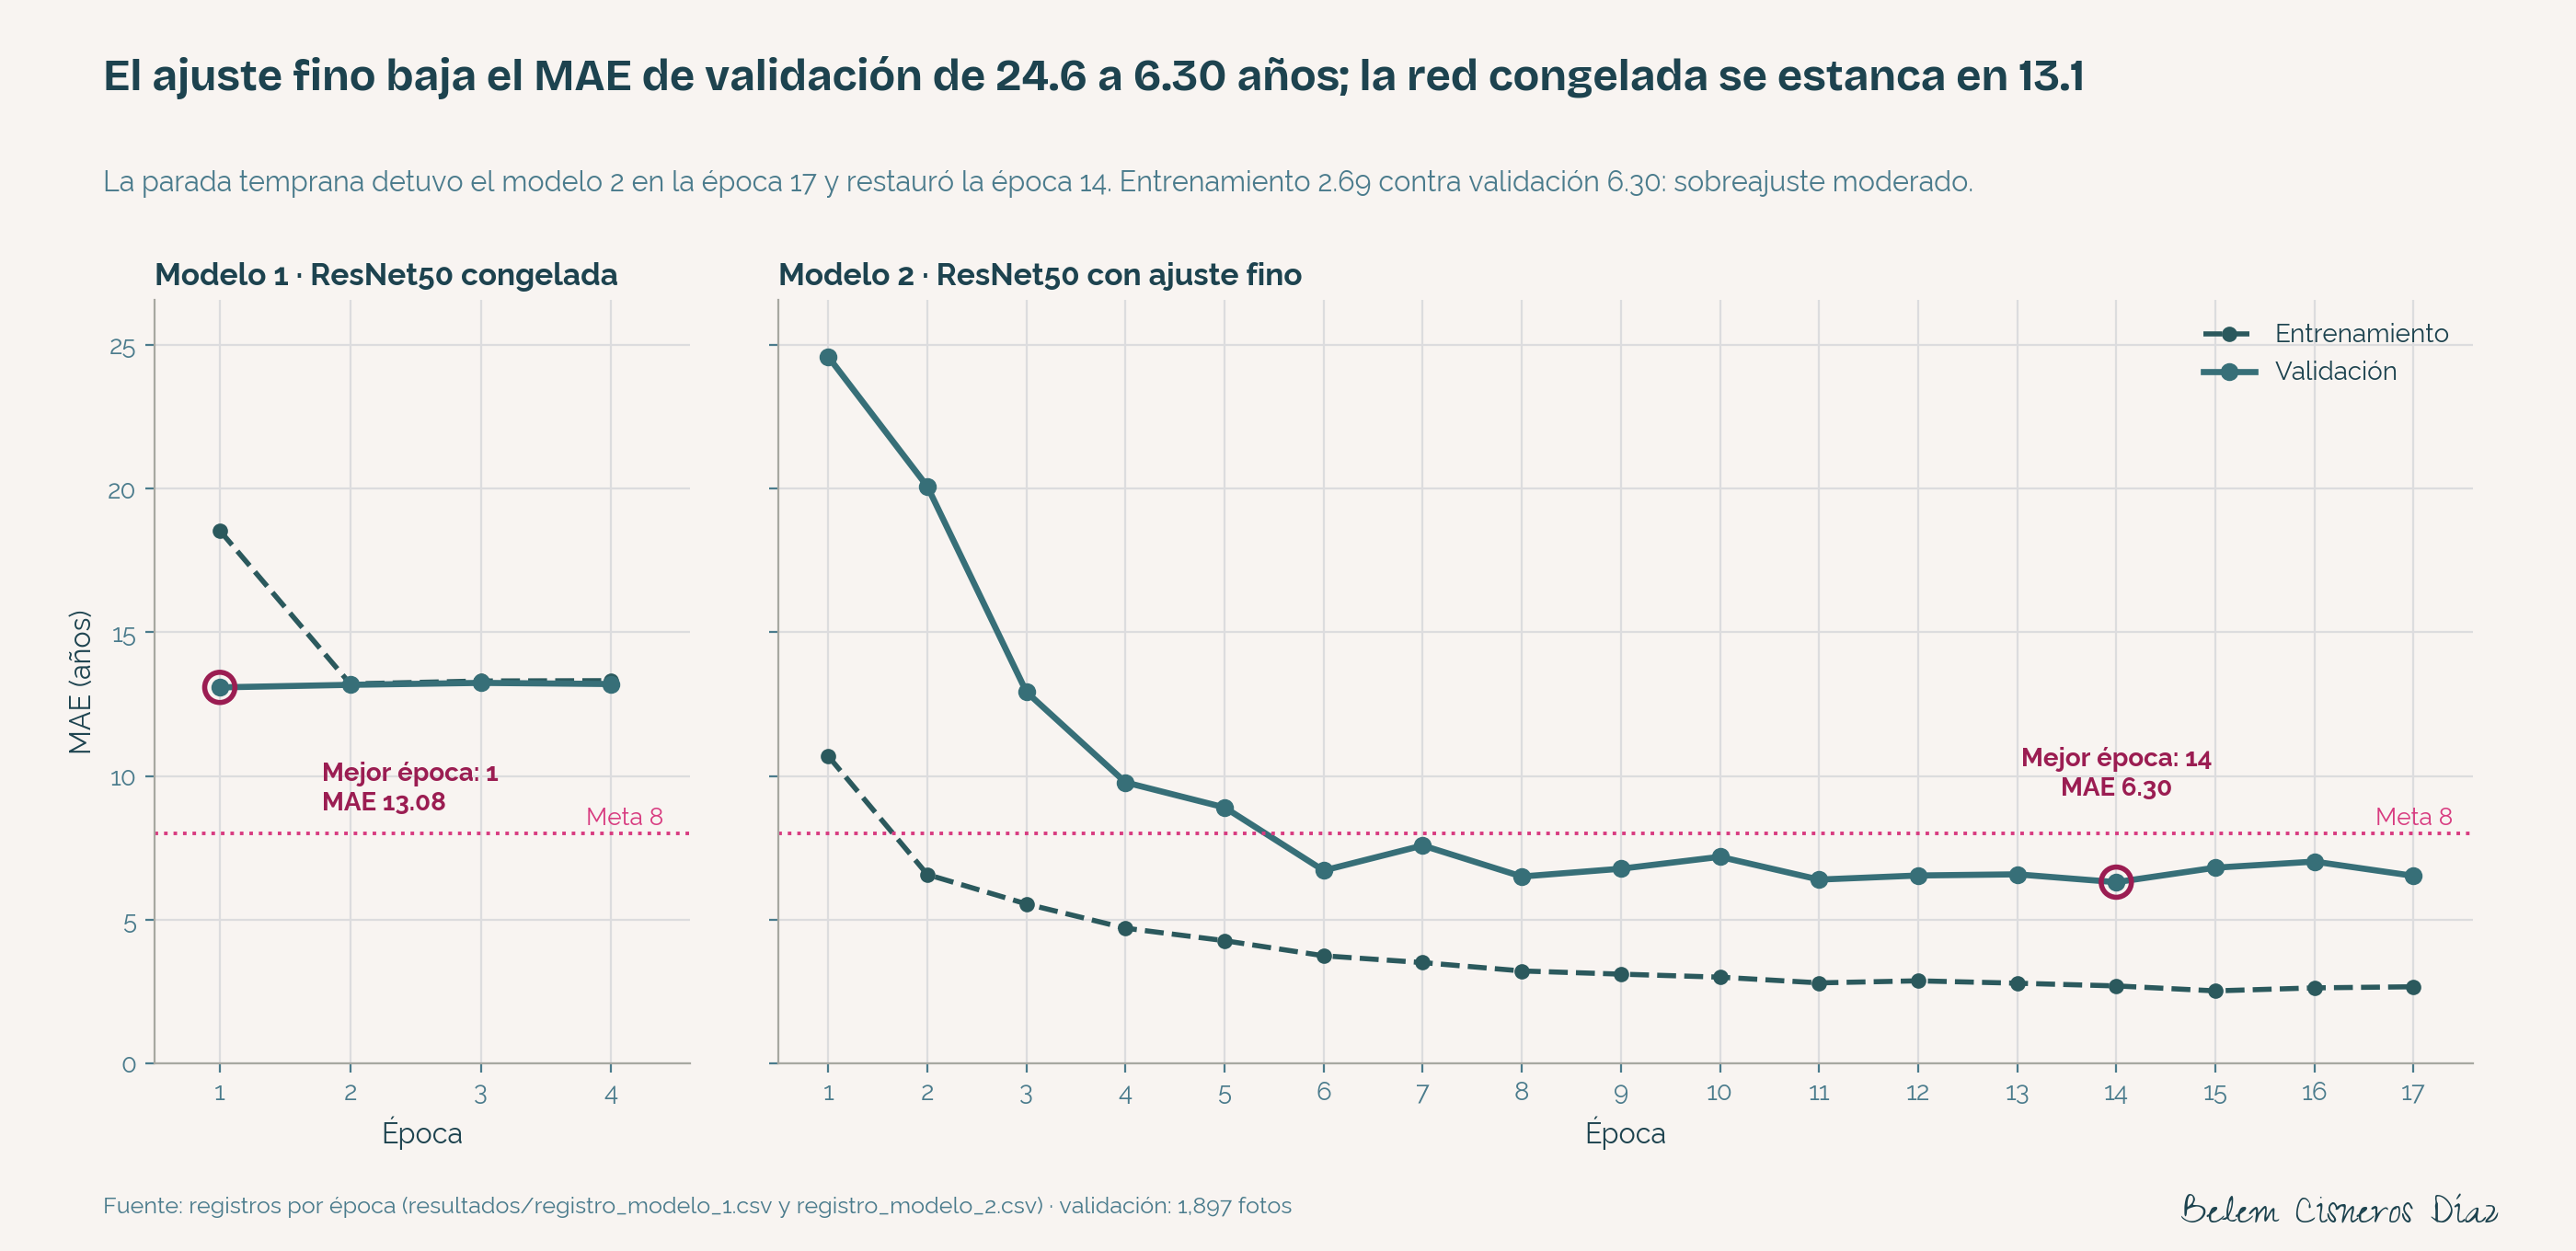

In [5]:
figura('02_comparacion_modelos.png')
figura('03_curvas_aprendizaje.png')

- **El ajuste fino es indispensable.** El modelo 2 reduce el error en 52% respecto a la línea base y cumple la meta con holgura (MAE de 6.30, intervalo de confianza de 6.05 a 6.55).
- **La red congelada no aprende la edad.** Su MAE (13.08) es igual al del modelo constante, y sus estimaciones casi no varían (desviación estándar de 1.06 años). Los filtros de ImageNet, entrenados con objetos y no con rostros, y con una normalización distinta (`preprocess_input`), no bastan sin reentrenarse.
- **Sobreajuste moderado y controlado.** En la mejor época (14), el MAE de entrenamiento es 2.69 y el de validación 6.30. La parada temprana detuvo el entrenamiento en la época 17, cuando la validación dejó de mejorar.

## 6. Error por grupo de edad

In [6]:
por_grupo = pd.DataFrame(metricas['error_por_grupo']['modelo_2']).set_index('grupo')
por_grupo['IC 95% del MAE'] = [
    f'{metricas["intervalos_95_bootstrap"][f"mae_{g}"][0]:.2f} a {metricas["intervalos_95_bootstrap"][f"mae_{g}"][1]:.2f}'
    for g in por_grupo.index
]
display(por_grupo.round(2))

,fotos,mae,sesgo,IC 95% del MAE
grupo,,,,
0-12,186,5.99,5.21,5.03 a 7.03
13-17,180,7.05,6.74,6.29 a 7.86
18-24,337,4.69,3.65,4.23 a 5.14
25-34,497,4.84,-0.41,4.52 a 5.15
35-49,411,7.19,-4.66,6.69 a 7.68
50-64,209,8.54,-5.11,7.43 a 9.49
65+,77,11.02,-10.41,9.10 a 13.24


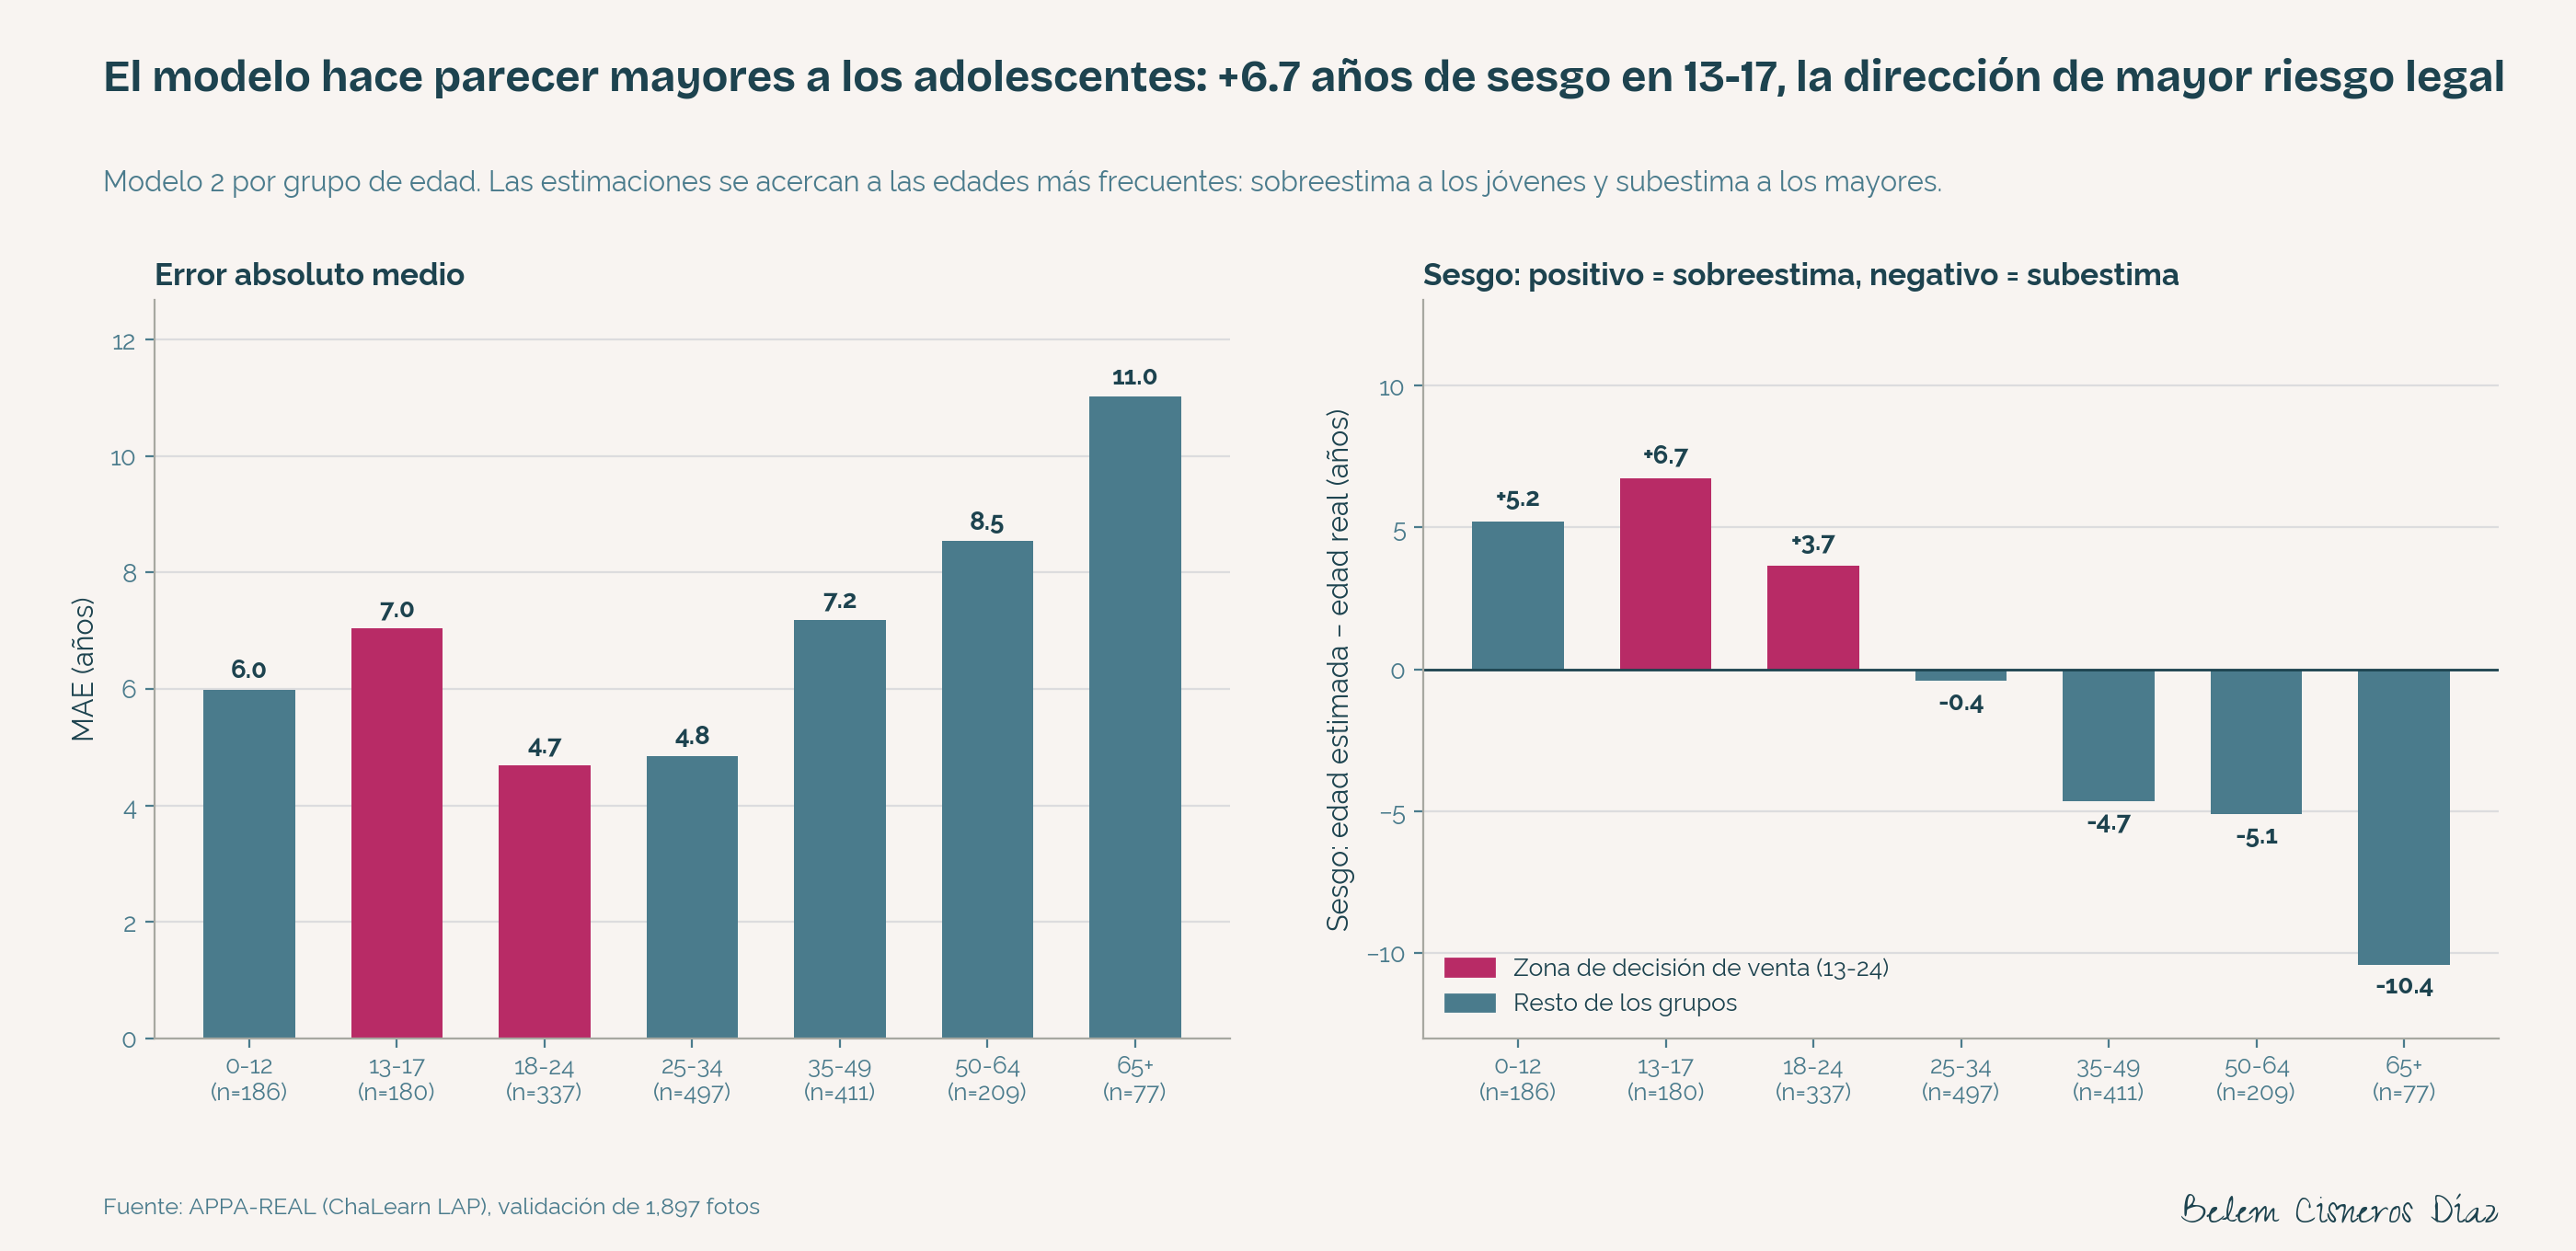

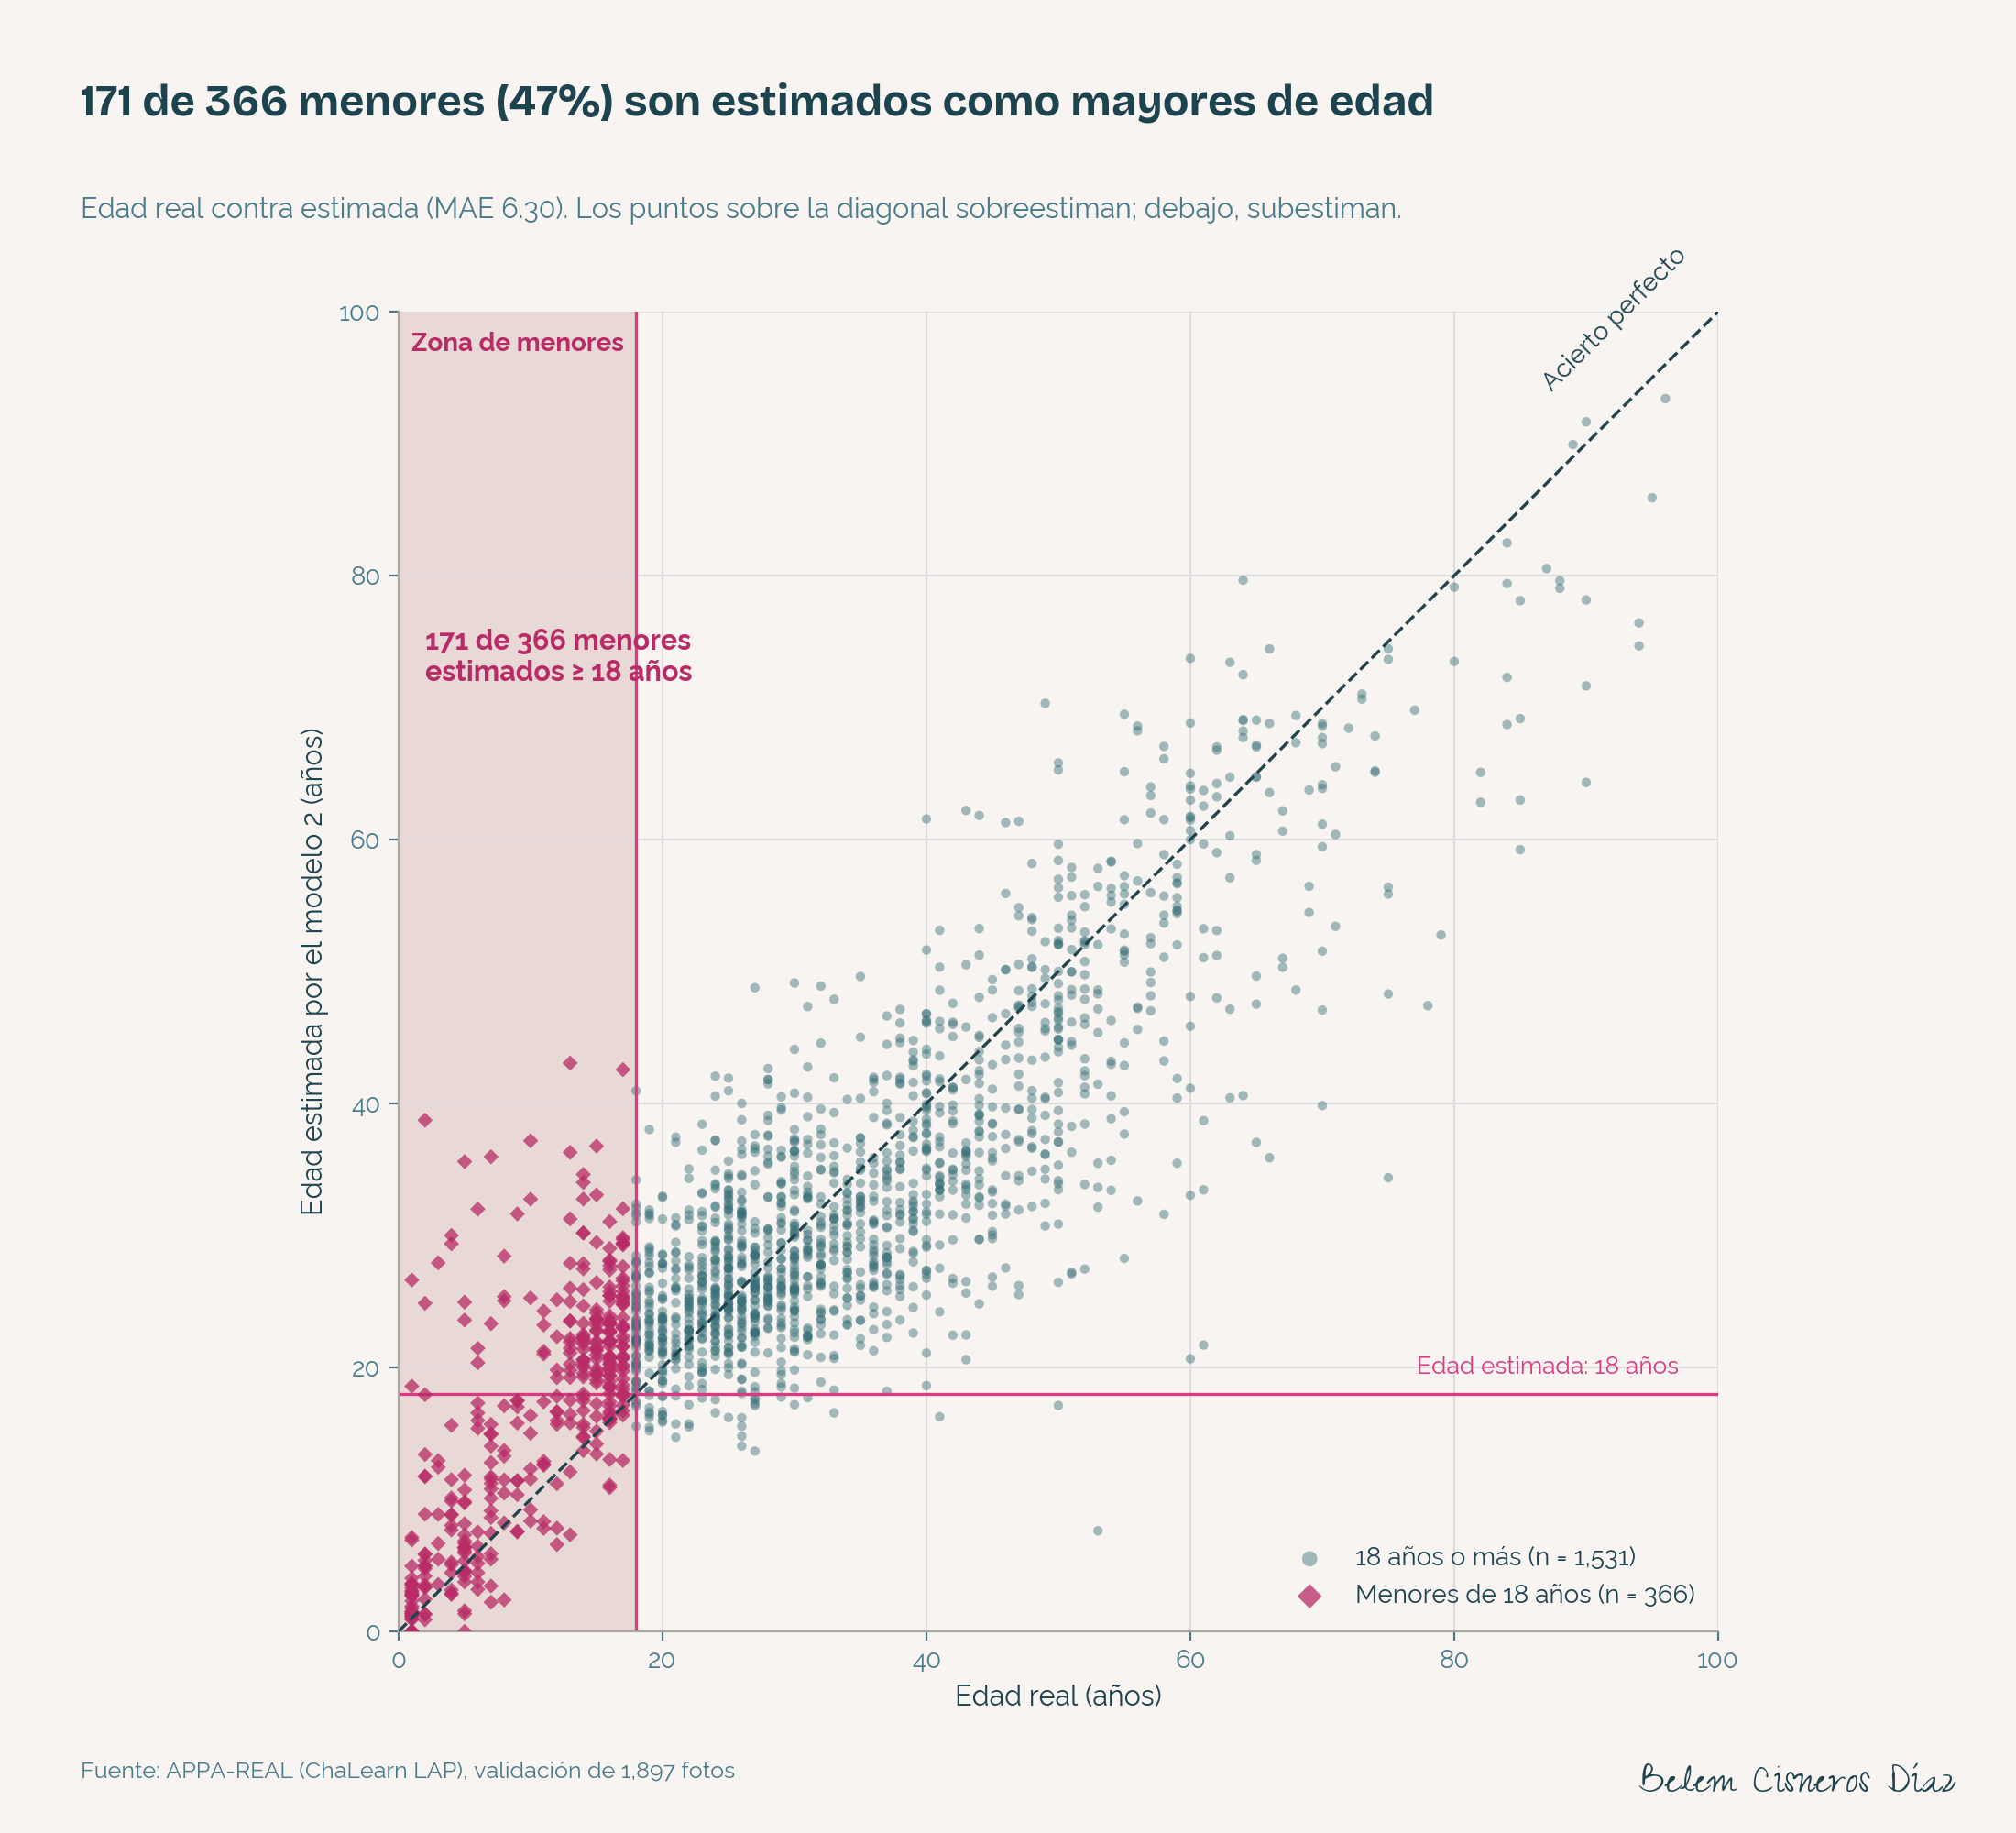

In [7]:
figura('04_error_por_grupo.png')
figura('05_real_vs_estimada.png')

- El error es menor en **18-24 (4.69)** y **25-34 (4.84)**, los grupos con más fotografías.
- El modelo **acerca sus estimaciones a las edades más frecuentes**: sobreestima a niños y jóvenes y subestima a adultos mayores (−10.41 años en 65+).
- En **13-17** el sesgo es de **+6.74 años**: en promedio, el modelo atribuye a los adolescentes más edad de la que tienen. Es la dirección de error de mayor riesgo legal. En la dispersión, 171 de los 366 menores de validación reciben una edad estimada de 18 años o más.

## 7. Política de umbral

El modelo no autoriza la venta: decide **a quién se le pide identificación**. Si la edad estimada es menor que un umbral T, el cajero solicita identificación. Para cada T de 18 a 30 años se calculan:

- **Menores no detectados:** porcentaje de menores con edad estimada ≥ T (riesgo legal).
- **Adultos a los que se pide identificación:** porcentaje de adultos con edad estimada < T (fricción en caja).

**Regla:** elegir el T más bajo con ≤ 1% de menores no detectados. Si ningún T la cumple, el modelo no se recomienda como filtro autónomo y se reporta el T con menos menores no detectados.

In [8]:
curva = pd.DataFrame(metricas['curva_umbral']).set_index('umbral')
display(curva.round(1))
umbral = metricas['umbral']
ic = metricas['intervalos_95_bootstrap']
display(Markdown(
    f"**Regla aplicada: {'principal' if umbral['regla'] == 'principal' else 'de respaldo (ningún umbral cumple el límite)'}.** Con T = {umbral['elegido']}, no se detectan "
    f"{umbral['menores_no_detectados_n']} de {metricas['menores_validacion']} menores "
    f"({umbral['menores_no_detectados_pct']:.1f}%, IC 95%: {ic['menores_no_detectados_pct'][0]:.1f}% a "
    f"{ic['menores_no_detectados_pct'][1]:.1f}%) y se pide identificación al "
    f"{umbral['adultos_con_identificacion_pct']:.1f}% de los adultos "
    f"(IC 95%: {ic['adultos_con_identificacion_pct'][0]:.1f}% a {ic['adultos_con_identificacion_pct'][1]:.1f}%)."
))

,menores_no_detectados_pct,adultos_con_identificacion_pct
umbral,,
18,46.7,2.9
19,44.5,4.5
20,39.6,5.9
21,33.9,7.8
22,28.7,10.7
23,24.3,15.3
24,18.9,19.7
25,16.1,24.1
26,12.6,28.9


**Regla aplicada: de respaldo (ningún umbral cumple el límite).** Con T = 30, no se detectan 21 de 366 menores (5.7%, IC 95%: 3.5% a 8.5%) y se pide identificación al 46.6% de los adultos (IC 95%: 44.0% a 49.2%).

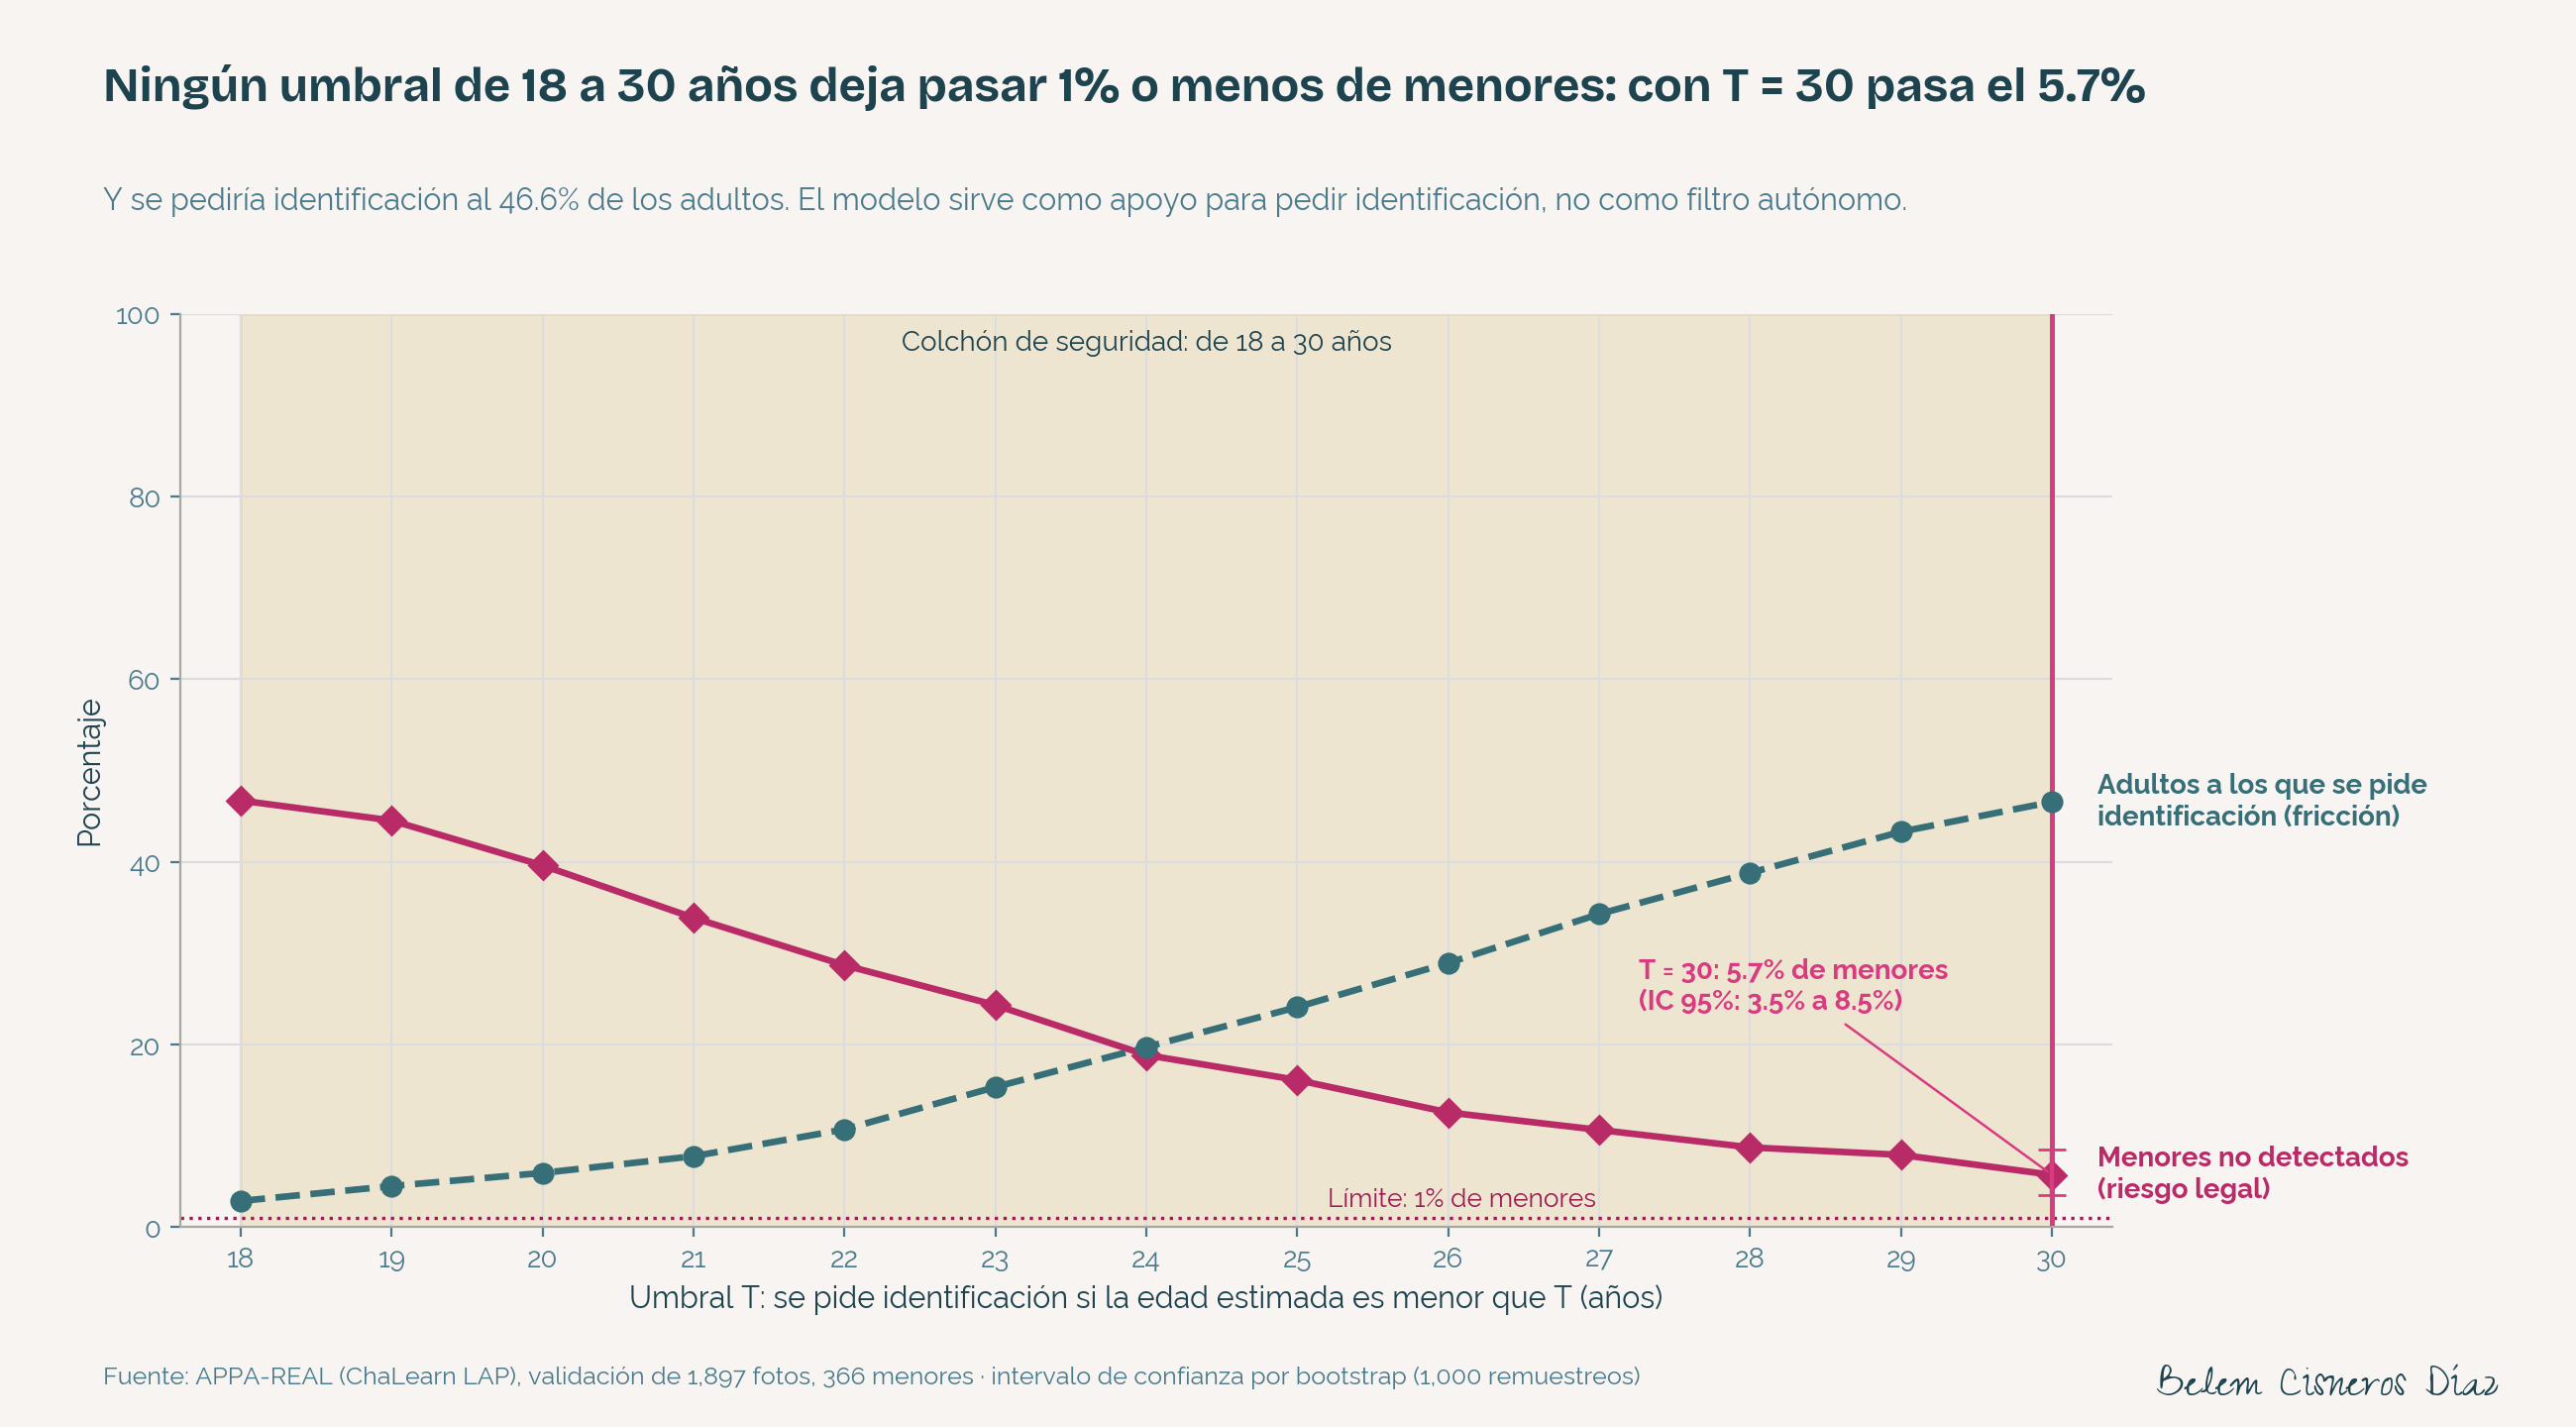

In [9]:
figura('06_compensacion_umbral.png')

Ningún umbral de 18 a 30 años cumple la regla. Incluso con T = 30 pasaría el 5.7% de los menores, y se pediría identificación a casi la mitad de los adultos. Como referencia, el regulador alemán de protección de menores (KJM) exige un colchón de 3 años sobre la edad mínima para aceptar la estimación facial, con sistemas comerciales que reportan un MAE de 1.1 años en adolescentes (Yoti, 2025). La distancia entre esa referencia y el MAE de 7.05 de este modelo en el grupo 13-17 explica por qué el umbral no se puede ajustar a un nivel aceptable.

## 8. Lógica de negocio

### 8.1 Costo de no cumplir en la Ciudad de México

| Concepto | Unidades de Cuenta | Pesos (Unidad de Cuenta 2025 = 113.14) | Fuente |
|---|---|---|---|
| Multa por permitir el acceso o la venta de alcohol a menores (Ley de Establecimientos Mercantiles) | 300 a 700 | 33,942 a 79,198 | Expansión, 2024 |
| Sanción adicional en caso de clausura (artículo 69) | 1,000 a 3,000 | 113,140 a 339,420 | Posta, 2025 |

En 2025 se habían clausurado 565 establecimientos en operativos que atienden denuncias que incluyen la venta de alcohol a menores (Expansión, mayo de 2025). Una sola clausura evitada supera los 113,000 pesos en sanciones, sin contar las ventas perdidas durante el cierre ni el daño reputacional. *No se encontró una publicación oficial accesible del valor 2026 de la Unidad de Cuenta; los montos usan el valor de 2025.*

### 8.2 Beneficio operativo documentado en la industria

- Las verificaciones de edad representan **más del 50% de las intervenciones del personal** en cajas de autoservicio (Yoti con NCR, 2018).
- Con estimación facial de edad, Diebold Nixdorf redujo la verificación de **hasta 2 minutos a menos de 10 segundos** y la intervención humana en **75%** (caso de estudio, 2025).
- En la prueba regulatoria del Ministerio del Interior británico, la tecnología resolvió **hasta el 40% de las verificaciones**, el **70% de los clientes** dijo que la usaría (techUK, 2023) y, según el proveedor, ningún menor logró comprar productos restringidos (Euronews, 2023).

### 8.3 Valor social

En América Latina, obtener alcohol en una tienda se asocia con un riesgo casi tres veces mayor de consumo excesivo mensual en estudiantes de 13 a 15 años, y que se les niegue la compra reduce ese riesgo (Probst et al., 2018). La industria de bebidas en México reporta más de mil millones de pesos invertidos en prevención en cinco años, con campañas como "No te hagas güey" de Cerveceros de México (Guadalajara Reporter, 2026). Un control consistente en caja contribuye directamente a ese objetivo.

### 8.4 Escenario por tienda (supuestos explícitos)

Good Seed es un cliente ficticio: el siguiente cálculo es un **escenario ilustrativo**, no una cifra real del cliente.

In [10]:
supuestos = {
    'ventas de alcohol por tienda al día': 150,
    'minutos por verificación manual': 1.0,
    'días de operación al año': 365,
    'proporción de verificaciones resueltas por la tecnología (referencia: prueba británica)': 0.40,
}
ventas = supuestos['ventas de alcohol por tienda al día']
minutos = supuestos['minutos por verificación manual']
dias = supuestos['días de operación al año']
automatizable = supuestos['proporción de verificaciones resueltas por la tecnología (referencia: prueba británica)']
pedir_id_actual = metricas['umbral']['adultos_con_identificacion_pct'] / 100

escenarios = pd.DataFrame({
    'escenario': ['A · Prototipo actual (MAE 6.30, T = 30)', 'B · Precisión comercial (MAE ~1 en adolescentes)'],
    'uso del modelo': ['Activa la solicitud de identificación; la decisión es humana', 'Resuelve automáticamente parte de las verificaciones'],
    'horas de personal liberadas al año por tienda': [0.0, ventas * automatizable * minutos * dias / 60],
    'beneficio principal': ['Consistencia del control y evidencia ante una inspección', 'Tiempo de personal y menor fila en caja, además del cumplimiento'],
}).set_index('escenario')
display(pd.Series(supuestos, name='valor').to_frame())
display(escenarios.round(0))
print(f'Con el prototipo actual se pediría identificación al {pedir_id_actual:.1%} de los adultos, por lo que no se reduce el trabajo manual.')

,valor
ventas de alcohol por tienda al día,150.0
minutos por verificación manual,1.0
días de operación al año,365.0
proporción de verificaciones resueltas por la tecnología (referencia: prueba británica),0.4


,uso del modelo,horas de personal liberadas al año por tienda,beneficio principal
escenario,,,
"A · Prototipo actual (MAE 6.30, T = 30)",Activa la solicitud de identificación; la deci...,0.0,Consistencia del control y evidencia ante una ...
B · Precisión comercial (MAE ~1 en adolescentes),Resuelve automáticamente parte de las verifica...,365.0,"Tiempo de personal y menor fila en caja, ademá..."


Con el prototipo actual se pediría identificación al 46.6% de los adultos, por lo que no se reduce el trabajo manual.


**Justificación de la inversión**

- **Las cámaras ya existen.** La inversión se limita al desarrollo del modelo, al cómputo y a la integración con la caja.
- **Escenario A (prototipo actual).** No reduce verificaciones manuales, pero estandariza el control: cada compra con edad estimada baja dispara la solicitud de identificación, sin depender del criterio de cada cajero, y deja registro de cada caso. Su retorno es el riesgo evitado: **una sola clausura evitada supera los 113,000 pesos en sanciones.**
- **Escenario B (precisión comercial).** Con un error cercano al de los sistemas comerciales, el modelo podría resolver por sí mismo una parte de las verificaciones. Bajo los supuestos anteriores, eso libera alrededor de **365 horas de personal al año por tienda**, además de reducir la fila en caja.
- **Ruta recomendada.** Implementar el escenario A como piloto y, en paralelo, mejorar el modelo hasta un error en adolescentes compatible con un colchón de 3 años. Para lograrlo: más fotografías de 13 a 24 años, partir de modelos preentrenados en rostros y validar con imágenes de las cámaras de las cajas.

**Cumplimiento de datos personales.** La Ley Federal de Protección de Datos Personales en Posesión de los Particulares (DOF, 20 de marzo de 2025) considera sensibles los datos cuyo uso indebido pueda dar origen a discriminación o conllevar un riesgo grave; su lista es enunciativa. Para esos datos, el artículo 8 exige consentimiento expreso y por escrito. Una implementación debe tratar la foto del rostro como dato sensible: aviso de privacidad, consentimiento y procesamiento sin almacenar las imágenes.

## 9. Conclusiones

1. **La visión artificial sí puede ayudar a Good Seed, como apoyo.** El modelo final estima la edad con un MAE de 6.30 años (meta: ≤ 8), pero no tiene precisión suficiente alrededor de los 18 años para autorizar ventas por sí solo.
2. **El riesgo está en los adolescentes.** El modelo sobreestima la edad del grupo 13-17 en 6.7 años en promedio; con T = 30 todavía pasaría el 5.7% de los menores.
3. **El uso recomendado es activar la solicitud de identificación** de forma consistente en cada compra de alcohol, con la decisión final en manos del cajero.
4. **Otras tareas que el cliente podría resolver con el modelo:** análisis agregado y anónimo de clientes por grupo de edad (surtido, promociones y personal por tienda y horario), medición del alcance de campañas por grupo de edad, verificación de otros productos con restricción de edad, como el tabaco, y alertas selectivas al personal en cajas de autoservicio.

## 10. Salvedades

- **Entrenamiento en CPU.** Se entrenó con procesador, no con GPU; los tiempos y las decisiones de configuración responden a ese entorno.
- **Pocos menores en validación.** Hay 366 menores de 18 años; un solo menor representa 0.27 puntos porcentuales de la tasa de menores no detectados. Por eso se reportan intervalos de confianza.
- **Edad real, no aparente.** Las etiquetas son la edad real; un cajero juzga la edad aparente, que APPA-REAL también ofrece y que podría ser más adecuada para comparar contra el criterio humano.
- **Validación con triple función.** El conjunto de validación se usó para la parada temprana, para elegir el modelo y para fijar el umbral, por lo que las métricas pueden ser ligeramente optimistas. Además, se usó una partición aleatoria propia (75/25) y no la partición oficial de APPA-REAL.
- **Normalización.** Se usó `rescale=1/255` en lugar del preprocesamiento original de ResNet50, lo que pudo perjudicar especialmente a la red congelada.
- **Sin detección de vida.** El modelo no incluye *liveness*, mecanismo que impide engañar al sistema con la fotografía de otra persona.
- **Sin análisis por sexo o tono de piel.** `labels.csv` no incluye esos atributos, así que no se pudo medir si el error cambia entre grupos demográficos.
- **Privacidad.** Ninguna fotografía se publica; las figuras solo muestran edades y estimaciones.

## 11. Fuentes

- Agustsson, E. et al. (2017). *Apparent and real age estimation in still images with deep residual regressors on APPA-REAL database*. FG 2017. Descripción del conjunto: https://chalearnlap.cvc.uab.cat/dataset/26/description/
- Guerrero Chiprés, S. (28 de junio de 2024). *Diversión segura y responsabilidad empresarial*. Expansión Política. https://politica.expansion.mx/voces/2024/06/28/columnainvitada-diversion-segura-y-responsabilidad-empresarial
- Posta (10 de junio de 2025). *Operativo nocturno deja 38 chelerías fuera de servicio*. https://www.posta.com.mx/cdmx/operativo-nocturno-deja-38-chelerias-fuera-de-servicio-conoce-cuanto-debes-pagar-si-cierran-tu-local/vl2050638
- Expansión Política (mayo de 2025). *Locales suspendidos en la CDMX por operativos contra la venta ilegal de alcohol*. https://politica.expansion.mx/cdmx/2025/05/09/locales-suspendidos-cdmx-operativos-venta-ilegal-alcohol
- Yoti (17 de octubre de 2018). *Streamlining the self-checkout experience with NCR*. https://www.yoti.com/blog/streamlining-the-self-checkout-experience-with-ncr/
- Yoti y Diebold Nixdorf (2025). *Case study*. https://yoti.com/wp-content/uploads/2025/02/Diebold_Nixdorf_Case-Study_040225_V2.pdf
- techUK (7 de abril de 2023). *How digital age verification can transform the self-checkout*. https://www.techuk.org/insights/guest-insights/how-digital-age-verification-can-transform-the-self-checkout-techukdigitaltrade
- Euronews (9 de enero de 2023). *Trial of a face scanner that estimates your age*. https://www.euronews.com/2023/01/09/trial-of-a-face-scanner-that-estimates-your-age-may-spell-the-end-of-being-idd-buying-alco
- Yoti (22 de julio de 2025). *Facial age estimation reaches new accuracy for teenagers*. https://www.yoti.com/blog/yoti-facial-age-estimation-reaches-new-accuracy-for-teenagers-ready-for-online-safety-act-enforcement/
- Yoti (21 de octubre de 2025). *Age estimation approved by the KJM*. https://www.yoti.com/blog/age-estimation-approved-kjm-highest-age-assurance-level-18-adult-content/
- Probst, C. et al. (2018). Alcohol policy relevant indicators and alcohol use among adolescents in Latin America and the Caribbean. *Journal of Studies on Alcohol and Drugs*, 79(1), 49-57. Resumen: https://movendi.ngo/?p=40317
- Guadalajara Reporter (25 de junio de 2026). *Underage drinkers targeted*. https://theguadalajarareporter.net/index.php/news/news/regional/64742-underage-drinkers-targeted
- Ley Federal de Protección de Datos Personales en Posesión de los Particulares (DOF, 20 de marzo de 2025). https://www.diputados.gob.mx/LeyesBiblio/pdf/LFPDPPP.pdf

---

Proyecto desarrollado como parte del bootcamp de Data Science de TripleTen · **Belem Cisneros Díaz** · github.com/he1109-ci3l0